In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

# Standardise column names
df.columns = (
    df.columns.str.strip()
    .str.replace(r"[^A-Za-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Saving ecommerce_product_returns_dataset.csv to ecommerce_product_returns_dataset.csv
Dataset loaded successfully!
Dataset shape: (1206, 9)


,Order_ID,Product_ID,Product_Category,Size,Price,Customer_History,Delivery_Time,Return_Status,Return_Reason
0,ORD100001,SH-010,Shoes,9,2416.05,Repeat,3.9,No,Not Applicable
1,ORD100002,JN-005,Jeans,34,1781.45,Repeat,1.3,No,Not Applicable
2,ORD100003,JK-025,Jackets,M,4399.91,New,10.4,Yes,Size/Fit Issue
3,ORD100004,SH-026,Shoes,10,2776.33,Repeat,6.5,No,Not Applicable
4,ORD100005,TS-029,T-Shirts,XL,469.93,New,3.2,No,Not Applicable


In [3]:
required_columns = [
    "Order_ID", "Product_ID", "Product_Category", "Size",
    "Price", "Customer_History", "Delivery_Time",
    "Return_Status", "Return_Reason"
]

missing_columns = [c for c in required_columns if c not in df.columns]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

print("Missing values before cleaning:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Exact duplicate rows:", df.duplicated().sum())

# Remove duplicate records and duplicate order IDs
df = df.drop_duplicates().copy()
df = df.drop_duplicates(subset=["Order_ID"], keep="first").copy()

# Clean text columns
text_columns = [
    "Order_ID", "Product_ID", "Product_Category", "Size",
    "Customer_History", "Return_Status", "Return_Reason"
]

for col in text_columns:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace("", pd.NA)

# Convert numeric columns
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
df["Delivery_Time"] = pd.to_numeric(
    df["Delivery_Time"], errors="coerce"
)

# Normalise the target labels
status_map = {
    "yes": 1, "returned": 1, "return": 1, "true": 1, "1": 1,
    "no": 0, "not returned": 0, "not_returned": 0,
    "false": 0, "0": 0
}

df["Return_Status"] = (
    df["Return_Status"].str.lower().map(status_map)
)

# Standardise customer history
df["Customer_History"] = (
    df["Customer_History"].str.lower().replace({
        "first-time": "new",
        "first time": "new",
        "first_time": "new",
        "first order": "new",
        "repeat customer": "repeat",
        "returning": "repeat",
        "existing": "repeat"
    })
)

# Mark invalid numeric values as missing
df.loc[df["Price"] < 0, "Price"] = np.nan
df.loc[df["Delivery_Time"] < 0, "Delivery_Time"] = np.nan

# Exclude rows with missing target labels
df = df.dropna(subset=["Return_Status"]).copy()
df["Return_Status"] = df["Return_Status"].astype(int)

# Remove rows missing essential order/product/category information
df = df.dropna(
    subset=["Order_ID", "Product_ID", "Product_Category"]
).copy()

print("Dataset shape after cleaning:", df.shape)
print("\nMissing values after cleaning:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nReturn status counts (0 = No, 1 = Yes):")
display(df["Return_Status"].value_counts())

Missing values before cleaning:


,Missing Values
Order_ID,0
Product_ID,0
Product_Category,0
Size,14
Price,0
Customer_History,9
Delivery_Time,18
Return_Status,0
Return_Reason,12


Exact duplicate rows: 6
Dataset shape after cleaning: (1200, 9)

Missing values after cleaning:


,Missing Values
Order_ID,0
Product_ID,0
Product_Category,0
Size,14
Price,0
Customer_History,9
Delivery_Time,18
Return_Status,0
Return_Reason,12



Return status counts (0 = No, 1 = Yes):


,count
Return_Status,
0,868
1,332


In [4]:
total_orders = len(df)
returned_orders = int(df["Return_Status"].sum())
not_returned_orders = total_orders - returned_orders

return_rate = (
    returned_orders / total_orders * 100 if total_orders else 0
)

print("========== OVERALL RETURN ANALYSIS ==========")
print("Total orders:", total_orders)
print("Returned orders:", returned_orders)
print("Non-returned orders:", not_returned_orders)
print(f"Overall return rate: {return_rate:.2f}%")

print("\n========== DESCRIPTIVE STATISTICS ==========")
display(df[["Price", "Delivery_Time"]].describe().round(2))

print("\n========== CATEGORY ANALYSIS ==========")

category_summary = df.groupby("Product_Category").agg(
    Total_Orders=("Order_ID", "count"),
    Returned_Orders=("Return_Status", "sum"),
    Average_Price=("Price", "mean"),
    Average_Delivery_Days=("Delivery_Time", "mean")
)

category_summary["Return_Rate_%"] = (
    category_summary["Returned_Orders"]
    / category_summary["Total_Orders"] * 100
)

display(
    category_summary.sort_values(
        "Return_Rate_%", ascending=False
    ).round(2)
)

print("\n========== CUSTOMER ANALYSIS ==========")

customer_summary = df.groupby("Customer_History", dropna=False).agg(
    Total_Orders=("Order_ID", "count"),
    Returned_Orders=("Return_Status", "sum")
)

customer_summary["Return_Rate_%"] = (
    customer_summary["Returned_Orders"]
    / customer_summary["Total_Orders"] * 100
)

display(customer_summary.round(2))

========== OVERALL RETURN ANALYSIS ==========
Total orders: 1200
Returned orders: 332
Non-returned orders: 868
Overall return rate: 27.67%

========== DESCRIPTIVE STATISTICS ==========


,Price,Delivery_Time
count,1200.00,1182.00
mean,1700.54,5.45
std,987.75,2.86
min,214.22,1.10
25%,983.72,3.30
50%,1429.13,4.80
75%,2291.79,6.98
max,4979.94,15.00



========== CATEGORY ANALYSIS ==========


,Total_Orders,Returned_Orders,Average_Price,Average_Delivery_Days,Return_Rate_%
Product_Category,,,,,
Jeans,233,90,1677.82,5.39,38.63
Shoes,195,64,2205.15,5.62,32.82
Jackets,152,44,3315.29,5.64,28.95
T-Shirts,295,68,823.15,5.60,23.05
Dresses,207,47,1810.42,5.02,22.71
Accessories,118,19,832.23,5.49,16.10



========== CUSTOMER ANALYSIS ==========


,Total_Orders,Returned_Orders,Return_Rate_%
Customer_History,,,
new,457,152,33.26
repeat,734,176,23.98
<NA>,9,4,44.44


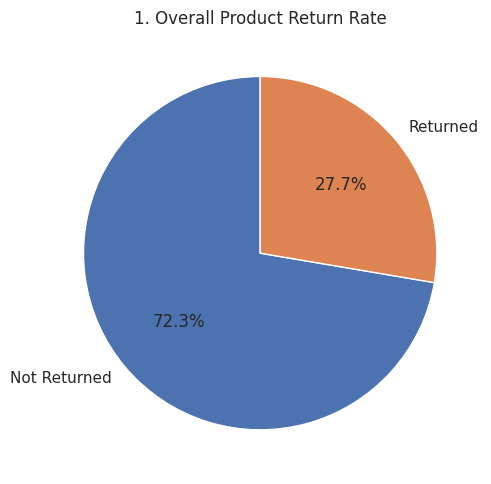

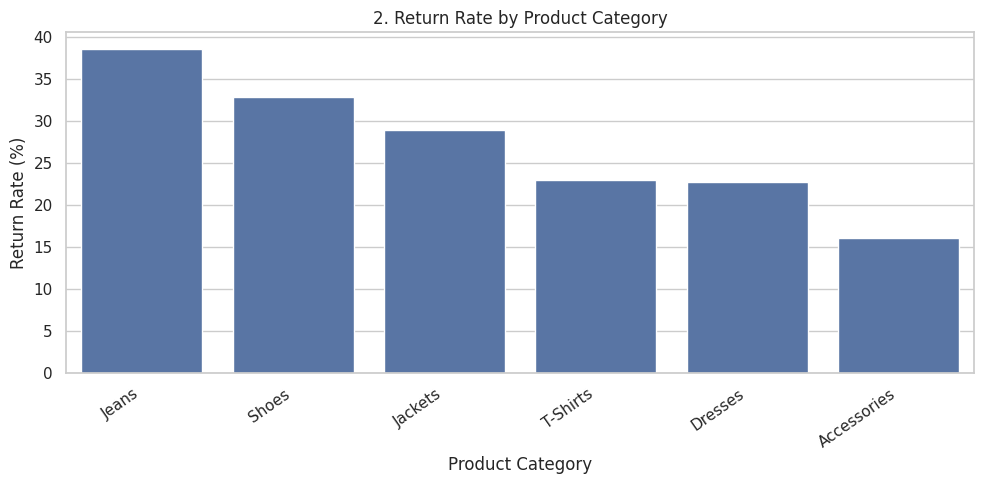

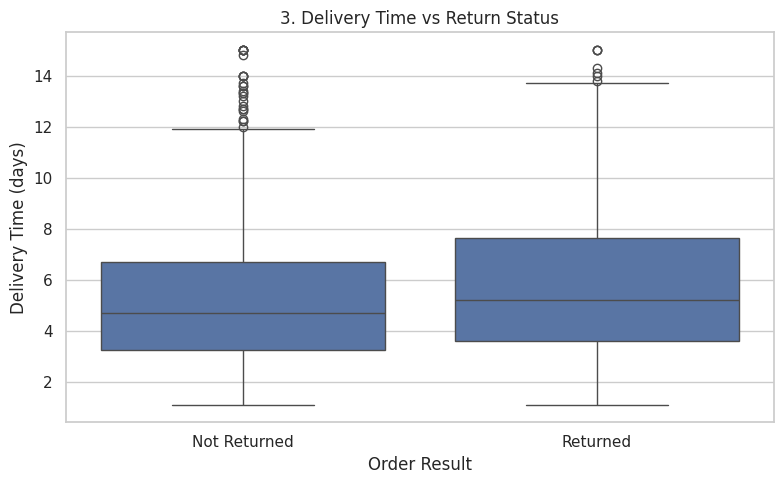

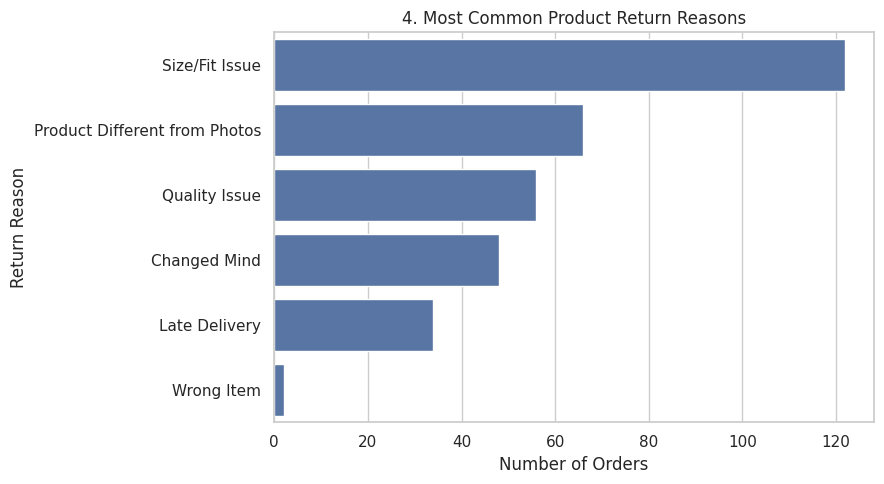

In [5]:
# VISUALIZATION 1: Overall return rate
status_counts = df["Return_Status"].map({
    0: "Not Returned",
    1: "Returned"
}).value_counts()

plt.figure(figsize=(7, 5))
plt.pie(
    status_counts.values,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("1. Overall Product Return Rate")
plt.tight_layout()
plt.show()


# VISUALIZATION 2: Return rate by category
category_plot = (
    df.groupby("Product_Category")
    .agg(
        Orders=("Order_ID", "count"),
        Return_Rate=("Return_Status", "mean")
    )
    .reset_index()
)

category_plot["Return_Rate"] *= 100
category_plot = category_plot.sort_values(
    "Return_Rate", ascending=False
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=category_plot,
    x="Product_Category",
    y="Return_Rate"
)
plt.title("2. Return Rate by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Return Rate (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


# VISUALIZATION 3: Delivery time comparison
delivery_data = df.dropna(subset=["Delivery_Time"]).copy()

delivery_data["Order_Result"] = delivery_data["Return_Status"].map({
    0: "Not Returned",
    1: "Returned"
})

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=delivery_data,
    x="Order_Result",
    y="Delivery_Time"
)
plt.title("3. Delivery Time vs Return Status")
plt.xlabel("Order Result")
plt.ylabel("Delivery Time (days)")
plt.tight_layout()
plt.show()


# VISUALIZATION 4: Most common return reasons
reason_data = df[
    (df["Return_Status"] == 1)
    & df["Return_Reason"].notna()
    & (df["Return_Reason"].str.lower() != "not applicable")
].copy()

reason_counts = reason_data["Return_Reason"].value_counts()

plt.figure(figsize=(9, 5))

if not reason_counts.empty:
    sns.barplot(
        x=reason_counts.values,
        y=reason_counts.index
    )
    plt.xlabel("Number of Orders")
    plt.ylabel("Return Reason")
else:
    plt.text(
        0.5, 0.5, "No recorded return reasons",
        ha="center", va="center"
    )
    plt.axis("off")

plt.title("4. Most Common Product Return Reasons")
plt.tight_layout()
plt.show()

In [6]:
print("========== DELIVERY TIME ANALYSIS ==========")

delivery_summary = df.groupby("Return_Status").agg(
    Orders=("Order_ID", "count"),
    Average_Delivery_Days=("Delivery_Time", "mean"),
    Median_Delivery_Days=("Delivery_Time", "median")
)

delivery_summary.index = delivery_summary.index.map({
    0: "Not Returned",
    1: "Returned"
})

display(delivery_summary.round(2))

print("\n========== RETURN REASONS ==========")

display(
    reason_data["Return_Reason"]
    .value_counts()
    .rename_axis("Return_Reason")
    .reset_index(name="Count")
)

print("\n========== PRODUCT-LEVEL ANALYSIS ==========")

product_summary = df.groupby("Product_ID").agg(
    Total_Orders=("Order_ID", "count"),
    Returned_Orders=("Return_Status", "sum"),
    Average_Price=("Price", "mean"),
    Average_Delivery_Days=("Delivery_Time", "mean")
)

product_summary["Return_Rate_%"] = (
    product_summary["Returned_Orders"]
    / product_summary["Total_Orders"] * 100
)

# Filter products with at least 5 orders for a more meaningful comparison
high_return_products = (
    product_summary[product_summary["Total_Orders"] >= 5]
    .sort_values("Return_Rate_%", ascending=False)
)

display(high_return_products.head(10).round(2))

print("\n========== NEW VS REPEAT CUSTOMERS ==========")
display(customer_summary.round(2))

========== DELIVERY TIME ANALYSIS ==========


,Orders,Average_Delivery_Days,Median_Delivery_Days
Return_Status,,,
Not Returned,868,5.28,4.7
Returned,332,5.91,5.2



========== RETURN REASONS ==========


,Return_Reason,Count
0,Size/Fit Issue,122
1,Product Different from Photos,66
2,Quality Issue,56
3,Changed Mind,48
4,Late Delivery,34
5,Wrong Item,2



========== PRODUCT-LEVEL ANALYSIS ==========


,Total_Orders,Returned_Orders,Average_Price,Average_Delivery_Days,Return_Rate_%
Product_ID,,,,,
JK-006,6,5,3241.18,5.02,83.33
JN-025,7,5,1529.80,5.93,71.43
SH-022,8,5,2696.26,7.28,62.50
SH-029,5,3,2087.51,4.26,60.00
JN-023,9,5,1813.61,5.13,55.56
SH-018,9,5,2154.38,4.80,55.56
JN-016,9,5,1746.78,3.81,55.56
JN-012,11,6,1513.36,5.96,54.55
JN-005,11,6,1701.93,4.87,54.55



========== NEW VS REPEAT CUSTOMERS ==========


,Total_Orders,Returned_Orders,Return_Rate_%
Customer_History,,,
new,457,152,33.26
repeat,734,176,23.98
<NA>,9,4,44.44


In [10]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

# Feature columns
features = [
    "Product_Category",
    "Size",
    "Price",
    "Customer_History",
    "Delivery_Time"
]

# Prepare features
X = df[features].copy()

# Normalize the target labels explicitly
y = (
    df["Return_Status"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "yes": "Returned",
        "no": "Not Returned",
        "1": "Returned",
        "0": "Not Returned",
        "true": "Returned",
        "false": "Not Returned",
        "returned": "Returned",
        "not returned": "Not Returned",
        "not_returned": "Not Returned"
    })
)

# Convert missing target values to standard NaN
y = y.astype(object)
y = y.where(pd.notna(y), np.nan)

# Remove rows with missing or invalid target labels
valid = y.isin(["Returned", "Not Returned"])
X = X.loc[valid].copy()
y = y.loc[valid].astype(str)

# Clean missing values in feature columns
X = X.astype(object).where(X.notna(), np.nan)

for col in ["Price", "Delivery_Time"]:
    X[col] = pd.to_numeric(X[col], errors="coerce")

categorical_features = [
    "Product_Category",
    "Size",
    "Customer_History"
]
numerical_features = ["Price", "Delivery_Time"]

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ]), numerical_features),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# Confirm there are two valid classes
print("Target distribution:")
print(y.value_counts())

if y.nunique() < 2:
    raise ValueError(
        "Return_Status must contain both Returned and Not Returned. "
        "Check the target values printed above."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

rf_model.fit(X_train, y_train)

print("\nRandom Forest model trained successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Target distribution:
Return_Status
Not Returned    868
Returned        332
Name: count, dtype: int64

Random Forest model trained successfully!
Training samples: 960
Testing samples: 240


In [11]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred = rf_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.6625

Classification Report:

              precision    recall  f1-score   support

Not Returned       0.72      0.86      0.79       174
    Returned       0.27      0.14      0.18        66

    accuracy                           0.66       240
   macro avg       0.50      0.50      0.48       240
weighted avg       0.60      0.66      0.62       240


Confusion Matrix:

[[150  24]
 [ 57   9]]


In [12]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = rf_model.predict(X_test)

print("MODEL EVALUATION")
print("-" * 40)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.2%}")
print(f"Precision: {precision_score(y_test, y_pred, pos_label='Returned', zero_division=0):.2%}")
print(f"Recall:    {recall_score(y_test, y_pred, pos_label='Returned', zero_division=0):.2%}")
print(f"F1 Score:  {f1_score(y_test, y_pred, pos_label='Returned', zero_division=0):.2%}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

MODEL EVALUATION
----------------------------------------
Accuracy:  66.25%
Precision: 27.27%
Recall:    13.64%
F1 Score:  18.18%

Classification Report:
              precision    recall  f1-score   support

Not Returned       0.72      0.86      0.79       174
    Returned       0.27      0.14      0.18        66

    accuracy                           0.66       240
   macro avg       0.50      0.50      0.48       240
weighted avg       0.60      0.66      0.62       240



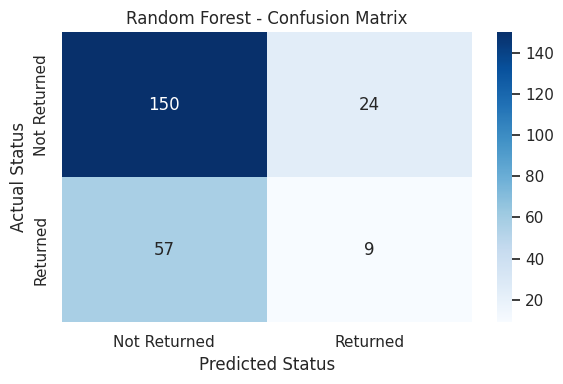

In [13]:

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Not Returned", "Returned"]
)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Returned", "Returned"],
    yticklabels=["Not Returned", "Returned"]
)
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

                                      Feature  Importance
0                              numeric__Price    0.379687
1                      numeric__Delivery_Time    0.341952
27          categorical__Customer_History_new    0.018260
23                        categorical__Size_S    0.017598
28       categorical__Customer_History_repeat    0.016995
7      categorical__Product_Category_T-Shirts    0.014955
24                       categorical__Size_XL    0.014131
21                        categorical__Size_M    0.014100
20                        categorical__Size_L    0.013597
5         categorical__Product_Category_Jeans    0.013412
3       categorical__Product_Category_Dresses    0.013126
2   categorical__Product_Category_Accessories    0.013038
25                       categorical__Size_XS    0.011502
26                      categorical__Size_XXL    0.011386
4       categorical__Product_Category_Jackets    0.009696


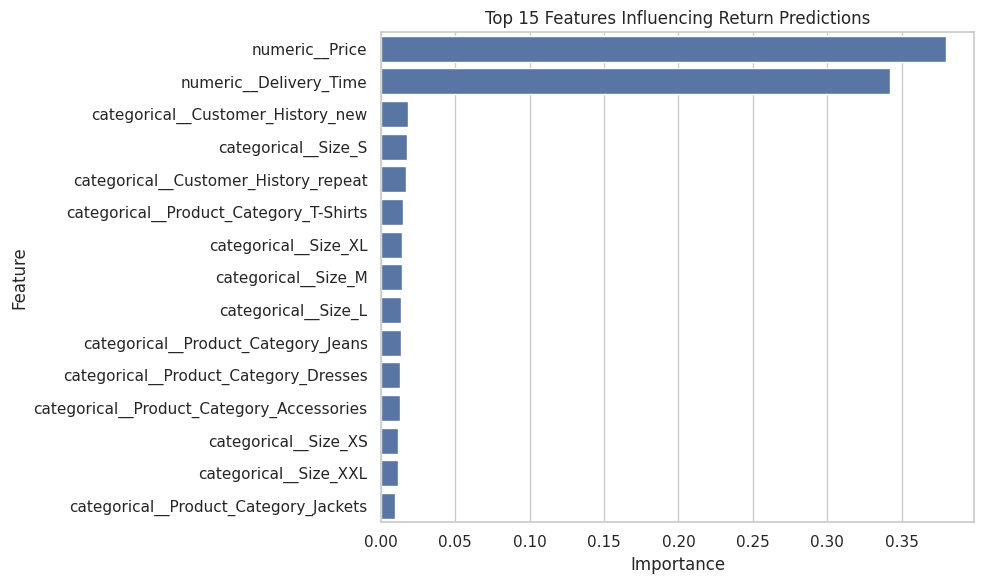

In [14]:

preprocessor_fitted = rf_model.named_steps["preprocessor"]
classifier = rf_model.named_steps["classifier"]

feature_names = preprocessor_fitted.get_feature_names_out()
importances = classifier.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print(importance_df.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Features Influencing Return Predictions")
plt.tight_layout()
plt.show()

In [15]:

# Overall return rate
return_rate = (df["Return_Status"] == "Returned").mean() * 100

# Return rate by category
category_returns = (
    df.groupby("Product_Category")
    .agg(
        Total_Orders=("Order_ID", "count"),
        Returned_Orders=("Return_Status",
                         lambda s: (s == "Returned").sum())
    )
)

category_returns["Return_Rate_%"] = (
    category_returns["Returned_Orders"]
    / category_returns["Total_Orders"] * 100
)

category_returns = category_returns.sort_values(
    "Return_Rate_%", ascending=False
)

# Return rate by customer history
customer_returns = (
    df.groupby("Customer_History")["Return_Status"]
    .apply(lambda s: (s == "Returned").mean() * 100)
    .sort_values(ascending=False)
)

print(f"Overall Return Rate: {return_rate:.2f}%")

print("\nCategories with Highest Return Rates:")
print(category_returns.round(2))

print("\nReturn Rate by Customer History:")
print(customer_returns.round(2))

# Delivery time comparison
print("\nAverage Delivery Time by Return Status:")
print(df.groupby("Return_Status")["Delivery_Time"].mean().round(2))

# Most common return reasons
if "Return_Reason" in df.columns:
    print("\nMost Common Return Reasons:")
    print(
        df.loc[df["Return_Status"] == "Returned", "Return_Reason"]
        .dropna()
        .value_counts()
        .head(10)
    )

Overall Return Rate: 0.00%

Categories with Highest Return Rates:
                  Total_Orders  Returned_Orders  Return_Rate_%
Product_Category                                              
Accessories                118                0            0.0
Dresses                    207                0            0.0
Jackets                    152                0            0.0
Jeans                      233                0            0.0
Shoes                      195                0            0.0
T-Shirts                   295                0            0.0

Return Rate by Customer History:
Customer_History
new       0.0
repeat    0.0
Name: Return_Status, dtype: float64

Average Delivery Time by Return Status:
Return_Status
0    5.28
1    5.91
Name: Delivery_Time, dtype: float64

Most Common Return Reasons:
Series([], Name: count, dtype: Int64)


In [16]:

action_plan = pd.DataFrame({
    "Finding to Investigate": [
        "Categories with high return rates",
        "Delivery delays and returns",
        "Common return reasons",
        "Repeated customer returns",
        "Products with high return rates"
    ],
    "Recommended Action": [
        "Review sizing, descriptions, quality and images",
        "Track delayed shipments and improve delivery estimates",
        "Address product defects, sizing problems or inaccurate descriptions",
        "Study return patterns and improve product recommendations",
        "Inspect product quality and supplier consistency"
    ],
    "Success Metric": [
        "Category return rate",
        "On-time delivery percentage",
        "Return rate by reason",
        "Repeat-customer return rate",
        "Product-level return rate"
    ]
})

display(action_plan)

,Finding to Investigate,Recommended Action,Success Metric
0,Categories with high return rates,"Review sizing, descriptions, quality and images",Category return rate
1,Delivery delays and returns,Track delayed shipments and improve delivery e...,On-time delivery percentage
2,Common return reasons,"Address product defects, sizing problems or in...",Return rate by reason
3,Repeated customer returns,Study return patterns and improve product reco...,Repeat-customer return rate
4,Products with high return rates,Inspect product quality and supplier consistency,Product-level return rate


In [17]:

import os
import joblib
import zipfile

output_dir = "ecommerce_analysis_results"
os.makedirs(output_dir, exist_ok=True)

# Save tables
category_returns.to_csv(
    f"{output_dir}/category_return_analysis.csv"
)
customer_returns.to_csv(
    f"{output_dir}/customer_return_analysis.csv"
)
importance_df.to_csv(
    f"{output_dir}/feature_importance.csv",
    index=False
)
action_plan.to_csv(
    f"{output_dir}/business_action_plan.csv",
    index=False
)

# Save model
joblib.dump(
    rf_model,
    f"{output_dir}/random_forest_return_model.pkl"
)

# Package results
with zipfile.ZipFile(
    "ecommerce_analysis_results.zip", "w",
    zipfile.ZIP_DEFLATED
) as zipf:
    for root, dirs, files in os.walk(output_dir):
        for file in files:
            path = os.path.join(root, file)
            zipf.write(path, arcname=os.path.relpath(path, output_dir))

from google.colab import files
files.download("ecommerce_analysis_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>